# Удовлетворённость авиапассажиров

## Исследование на данных Playground Series S6E10

Исследование показывает, как логистическая регрессия ранжирует записи по удовлетворённости пассажиров на основе характеристик поездки и оценок услуг. Также мы разбираем ошибки модели.

Данные: [Kaggle Playground Series S6E10](https://www.kaggle.com/competitions/playground-series-s6e10). Ноутбук использует официальный `train.csv`; метки конкурсного test недоступны. Данные синтетические, поэтому выводы ограничены этим набором.

### Как читать и запустить

Ноутбук содержит анализ данных, обучение и оценку модели. Обучение выполняет общий код проекта `src/train.py`; отдельный скриптовый запуск описан в [README](../README.md). Файл `data/train.csv` включён в репозиторий. Чтобы повторить расчёты, установите `requirements-notebook.txt` и запустите все ячейки. Вместо копирования можно задать переменную окружения `S6E10_DATA` с путём к файлу до запуска Jupyter.

При каждом полном запуске baseline обучается заново; результаты записываются в `outputs/notebook/`, который исключён из Git. В таблицах и на графиках ниже сохранён результат полного запуска.

In [1]:
import os
import sys
import json
import hashlib
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
import yaml
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay

root = Path.cwd().resolve()
if not (root / 'src' / 'train.py').exists():
    root = root.parent
if not (root / 'src' / 'train.py').exists():
    raise RuntimeError('Откройте ноутбук из каталога проекта или notebooks/.')
sys.path.insert(0, str(root))
from src.train import NUMS, CATS, build_pipeline

data_path = Path(os.environ.get('S6E10_DATA', root / 'data' / 'train.csv')).expanduser()
if not data_path.is_file():
    raise FileNotFoundError('Нужен train.csv в data/ или путь через S6E10_DATA. Инструкция: README.md')
output_dir = root / 'outputs' / 'notebook'
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
BLUE, ORANGE = '#2456a6', '#da7043'
pd.set_option('display.max_columns', 30)

## 1. Постановка

Объект наблюдения в этом исследовании: строка набора. Целевая переменная `satisfaction` показывает, удовлетворён ли пассажир; `True` считаем положительным классом. На вход модели поступает 21 признак поездки, пассажира и услуг. `id` исключён. Модель выдаёт скор для ранжирования.

**Гипотеза:** логистическая регрессия по доступным признакам ранжирует записи лучше случайного порядка. Оценки отдельных услуг могут содержать информацию об итоговом ответе. Такую связь не следует считать причинной.

Предполагается, что оценки услуг уже известны. В таком случае ранжирование могло бы помочь отобрать анкеты с признаками неудовлетворённости для изучения проблем сервиса. Оценки могут быть получены после полёта и в том же опросе, что и целевой ответ. Польза модели на реальных данных и её применимость до вылета не проверялись.

## 2. Данные и первые проверки

Проверим размер выборки, состав классов и пропуски. Контрольная сумма подтвердит, что используется та же версия файла, для которой сделаны выводы в ноутбуке.

In [2]:
sha = hashlib.sha256()
with data_path.open('rb') as stream:
    for block in iter(lambda: stream.read(1024 * 1024), b''):
        sha.update(block)
expected_sha = '2313b65c74e6994f01c2628aae82d2f97aa6f74a81950172ff83864837c98b36'
if sha.hexdigest() != expected_sha:
    raise ValueError('Хеш train.csv отличается от версии исследования. Проверьте входной файл.')
data = pd.read_csv(data_path)
labels = data['satisfaction'].astype(str).str.lower().map({'true': 1, 'false': 0})
assert labels.notna().all() and set(data.columns) == set(NUMS + CATS + ['id', 'satisfaction'])
summary = pd.DataFrame({'значение': [len(data), len(NUMS + CATS), int(labels.sum()),
                                       int((1-labels).sum()), sha.hexdigest()]},
                       index=['Строки', 'Признаки', 'Удовлетворён', 'Не удовлетворён', 'SHA-256'])
display(summary)

,значение
Строки,699635
Признаки,21
Удовлетворён,310339
Не удовлетворён,389296
SHA-256,2313b65c74e6994f01c2628aae82d2f97aa6f74a819501...


,Пропуски
Arrival Delay in Minutes,292


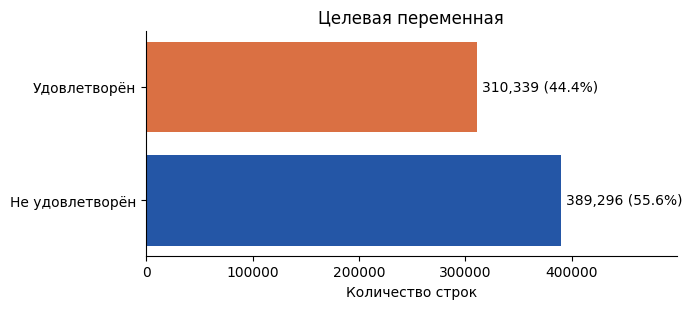

In [3]:
missing = data.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False).rename('Пропуски').to_frame()
display(missing if len(missing) else pd.DataFrame({'Пропуски': [0]}, index=['Нет пропусков']))
class_counts = labels.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(['Не удовлетворён', 'Удовлетворён'], class_counts, color=[BLUE, ORANGE])
ax.bar_label(bars, labels=[f'{v:,} ({v/len(data):.1%})' for v in class_counts], padding=4)
ax.set(xlabel='Количество строк', title='Целевая переменная'); ax.set_xlim(0, class_counts.max()*1.28)
plt.tight_layout(); plt.show()

Положительных ответов около 44%; сильного дисбаланса классов нет. Пропуски обнаружены только в задержке прилёта. При оценке медиана для их заполнения вычисляется отдельно на обучающей части каждого фолда.

In [4]:
print('Числовые и порядковые признаки:', len(NUMS))
print('Категориальные признаки:', len(CATS))
display(pd.DataFrame({'Тип': ['Числовые и порядковые', 'Категориальные'],
                      'Столбцы': [', '.join(NUMS), ', '.join(CATS)]}).set_index('Тип'))
feature_duplicates = data.duplicated(subset=NUMS + CATS, keep=False)
print(f'Строк с точным совпадением всех 21 признака: {feature_duplicates.sum():,}')

Числовые и порядковые признаки: 17
Категориальные признаки: 4


,Столбцы
Тип,
Числовые и порядковые,"Age, Flight Distance, Inflight wifi service, D..."
Категориальные,"Gender, Customer Type, Type of Travel, Class"


Строк с точным совпадением всех 21 признака: 0


Мы не нашли строк с полным совпадением всех 21 признака. Проверка не ищет близкие наблюдения и не доказывает их независимость. Значение нуля в оценках услуг не установлено, поэтому baseline сохраняет его как числовое значение. Названия признаков сами по себе не доказывают ни утечку, ни доступность в конкретный момент.

### Распределения признаков

Посмотрим на возраст, дальность полёта и долю положительных ответов в категориях. Графики описывают весь train; качество модели и причинное влияние признаков они не оценивают.

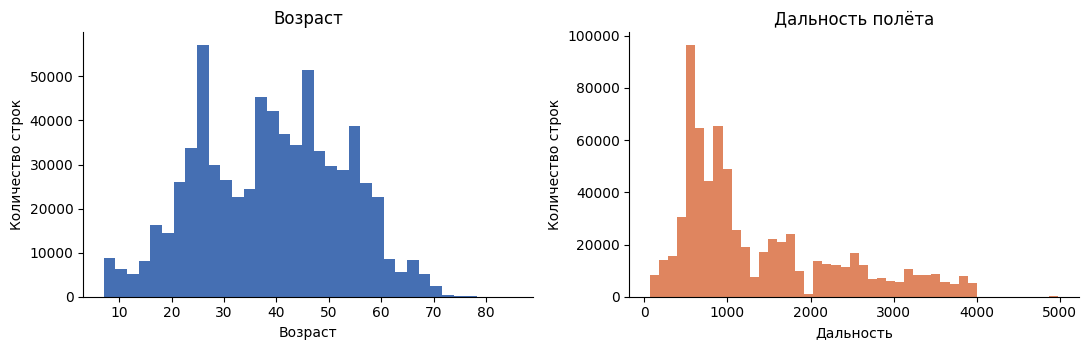

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(data['Age'], bins=35, color=BLUE, alpha=.85)
axes[0].set(title='Возраст', xlabel='Возраст', ylabel='Количество строк')
axes[1].hist(data['Flight Distance'], bins=45, color=ORANGE, alpha=.85)
axes[1].set(title='Дальность полёта', xlabel='Дальность', ylabel='Количество строк')
fig.tight_layout(); plt.show()

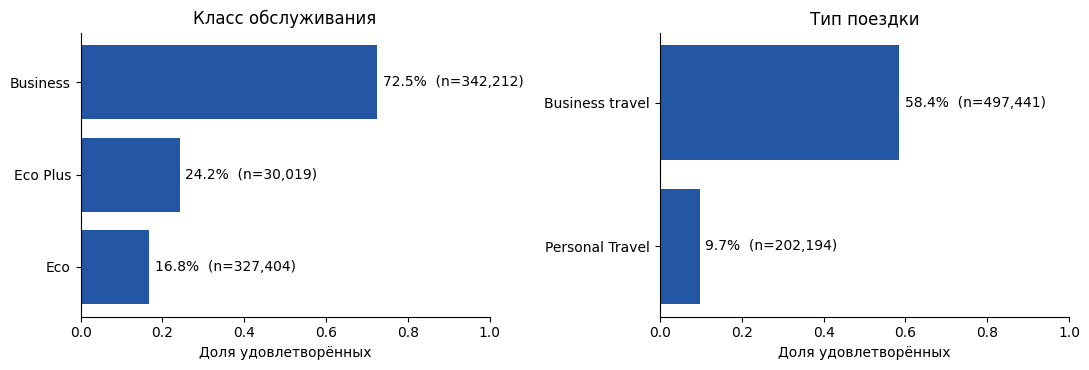

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title in zip(axes, ['Class', 'Type of Travel'], ['Класс обслуживания', 'Тип поездки']):
    rates = data.assign(positive=labels).groupby(col, observed=True)['positive'].agg(['mean', 'size']).sort_values('mean')
    bars = ax.barh(rates.index, rates['mean'], color=BLUE)
    ax.bar_label(bars, labels=[f'{v:.1%}  (n={n:,})' for v, n in zip(rates['mean'], rates['size'])], padding=4)
    ax.set_xlim(0, 1); ax.set(xlabel='Доля удовлетворённых', title=title)
fig.tight_layout(); plt.show()

Доли положительных ответов различаются между классами обслуживания и типами поездки. Группы могут различаться по многим признакам одновременно, поэтому по этим графикам нельзя заключить, что класс или тип поездки вызвал различие в удовлетворённости.

## 3. Baseline и протокол

В качестве baseline используем одну логистическую регрессию. Числовые признаки заполняются медианой и стандартизируются; категориальные заполняются модой и кодируются one-hot. Оценки услуг трактуются как числовые, поэтому модель предполагает линейный вклад каждого уровня в логит. Это ограничение можно проверить сравнением с нелинейной моделью.

Используем **5 стратифицированных фолдов**, `seed=42` и ROC-AUC. Стратификация сохраняет примерно одинаковую долю классов. На каждом фолде предобработка и модель обучаются только на его обучающей части; каждая строка получает один out-of-fold (OOF) прогноз. ROC-AUC измеряет долю правильно упорядоченных пар положительной и отрицательной строк. При равных скорах пара получает половину балла.

Такой протокол оценивает случайные разбиения этого набора. Он не проверяет перенос во времени или на новые группы. Конкурсный поиск уже использовал эти данные, поэтому новая проверка зависит от предыдущей работы с набором.

In [7]:
import inspect
from IPython.display import Code
cfg = yaml.safe_load((root / 'configs' / 'baseline.yaml').read_text())
reference = json.loads((root / 'reports' / 'metrics.json').read_text())
experiment = {k: v for k, v in cfg.items() if k not in ('data_path', 'output_dir')}
if experiment != reference['experiment_config']:
    raise ValueError('Конфигурация отличается от зафиксированного эксперимента. Для нового эксперимента используйте скриптовый запуск.')
display(pd.DataFrame({'значение': [cfg['n_splits'], cfg['seed'], cfg['model']['C'],
                                    cfg['model']['solver'], cfg['model']['max_iter']]},
                     index=['Фолды', 'Seed', 'C', 'Solver', 'Максимум итераций']))
print('Общая реализация модели и предобработки:')
display(Code(inspect.getsource(build_pipeline), language='python'))

,значение
Фолды,5
Seed,42
C,1.0
Solver,lbfgs
Максимум итераций,500


Общая реализация модели и предобработки:


def build_pipeline(cfg):
    """Построить baseline с обучаемой внутри фолда предобработкой."""
    numeric = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
    categorical = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                            ('onehot', OneHotEncoder(handle_unknown='ignore'))])
    prep = ColumnTransformer([('numeric', numeric, NUMS), ('categorical', categorical, CATS)])
    return Pipeline([('preprocess', prep),
                     ('model', LogisticRegression(**cfg['model'], random_state=cfg['seed']))])

In [8]:
# Вызов того же кода, что используется при запуске из командной строки.
# Путь к данным передаётся явно; команда не обращается к конкурсному test.
run = subprocess.run(
    [sys.executable, '-m', 'src.train', '--config', 'configs/baseline.yaml',
     '--data', str(data_path.resolve()), '--output', str(output_dir)],
    cwd=root, capture_output=True, text=True,
    env={**os.environ, 'OPENBLAS_NUM_THREADS': '1', 'OMP_NUM_THREADS': '1', 'MKL_NUM_THREADS': '1'},
)
if run.returncode:
    raise RuntimeError('Обучение завершилось ошибкой:\n' + run.stderr[-5000:])
metrics = json.loads((output_dir / 'metrics.json').read_text())
assert metrics['input_sha256'] == expected_sha
folds = pd.DataFrame(metrics['folds'])
display(folds[['fold', 'n_train', 'n_validation', 'roc_auc', 'average_precision', 'iterations']]
        .rename(columns={'fold':'Фолд', 'n_train':'Train', 'n_validation':'Validation',
                         'roc_auc':'ROC-AUC', 'average_precision':'Average precision', 'iterations':'Итерации'})
        .style.format({'ROC-AUC':'{:.6f}', 'Average precision':'{:.6f}'}))
print(f"ROC-AUC по фолдам: {metrics['mean_fold_auc']:.6f} ± {metrics['std_fold_auc_population']:.6f}")
print(f"Общий OOF ROC-AUC: {metrics['oof_auc']:.6f}; average precision: {metrics['oof_average_precision']:.6f}")

,Фолд,Train,Validation,ROC-AUC,Average precision,Итерации
0,1,559708,139927,0.922417,0.910068,22
1,2,559708,139927,0.921417,0.908925,22
2,3,559708,139927,0.921403,0.909723,22
3,4,559708,139927,0.921274,0.907459,22
4,5,559708,139927,0.921264,0.908696,20


ROC-AUC по фолдам: 0.921555 ± 0.000436
Общий OOF ROC-AUC: 0.921556; average precision: 0.908968


Модель превосходит ориентир случайного ранжирования: средний ROC-AUC по фолдам составляет 0,9216. Это подтверждает наличие предсказательного сигнала на выбранных разбиениях, но не практическую пригодность. Стандартное отклонение отражает разброс фолдов, но не даёт доверительного интервала: обучающие части пересекаются. Общий OOF ROC-AUC отличается от среднего по фолдам, поскольку сравнивает также скоры из разных фолдов.

## 4. Результаты и ошибки

ROC-кривая показывает соотношение долей истинных и ложных срабатываний при разных порогах. Кривая precision–recall дополняет её: пунктир соответствует доле положительного класса. Порог 0,5 выбран для описательного анализа ошибок ниже; калибровку вероятностей и оптимальность порога мы не проверяли.

Средний ROC-AUC совпадает с зафиксированным (до 0,000001): да


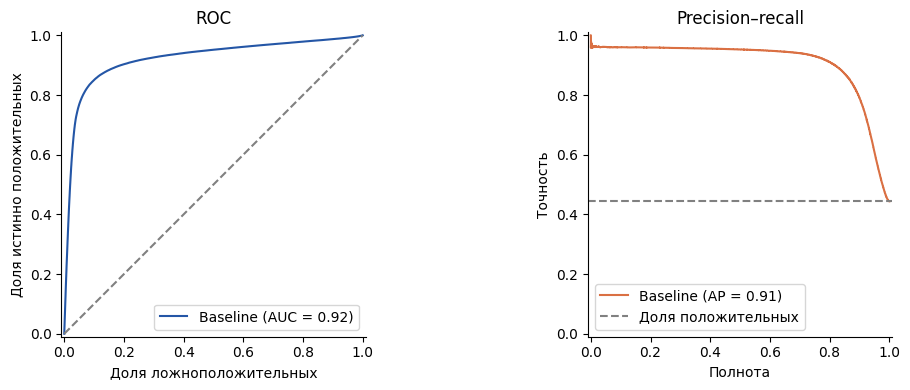

,Прогноз: не удовлетворён,Прогноз: удовлетворён
Факт: не удовлетворён,351511,37785
Факт: удовлетворён,47335,263004


In [9]:
oof = pd.read_csv(output_dir / 'oof.csv')
assert oof['id'].is_unique and len(oof) == len(data)
assert np.isclose(roc_auc_score(oof['target'], oof['score']), metrics['oof_auc'], rtol=0, atol=1e-12)
reference = json.loads((root / 'reports' / 'metrics.json').read_text())
print('Средний ROC-AUC совпадает с зафиксированным (до 0,000001):',
      'да' if np.isclose(metrics['mean_fold_auc'], reference['mean_fold_auc'], rtol=0, atol=1e-6) else 'нет; проверьте среду')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(oof.target, oof.score, ax=axes[0], name='Baseline', color=BLUE)
axes[0].plot([0,1], [0,1], '--', color='grey')
axes[0].set(title='ROC', xlabel='Доля ложноположительных', ylabel='Доля истинно положительных')
PrecisionRecallDisplay.from_predictions(oof.target, oof.score, ax=axes[1], name='Baseline', color=ORANGE)
axes[1].axhline(oof.target.mean(), linestyle='--', color='grey', label='Доля положительных')
axes[1].legend(); axes[1].set(title='Precision–recall', xlabel='Полнота', ylabel='Точность')
fig.tight_layout(); plt.show()
cm = pd.DataFrame(metrics['confusion_matrix_rows_true_columns_pred'],
                  index=['Факт: не удовлетворён', 'Факт: удовлетворён'],
                  columns=['Прогноз: не удовлетворён', 'Прогноз: удовлетворён'])
display(cm)

### Доверительный интервал ROC-AUC

Оценим разброс общего OOF ROC-AUC с помощью стратифицированного bootstrap. В каждом из 1 000 повторов мы выбираем строки с возвращением отдельно внутри положительного и отрицательного классов, сохраняя размер каждого класса. 95%-й процентильный интервал задаётся 2,5-м и 97,5-м процентилями. Число повторов и `seed=20261108` фиксированы.

Этот интервал относится к объединённым OOF-прогнозам, а не к среднему по фолдам. Он условен на уже обученных моделях и предполагает независимость строк внутри классов. Строки могут быть зависимы, а переобучение моделей и предыдущий выбор решений в эту оценку не входят. Поэтому интервал не подтверждает перенос на другие данные.

In [10]:
from src.bootstrap import bootstrap_auc

interval = bootstrap_auc(oof['target'], oof['score'], repetitions=1000, seed=20261108)
display(pd.DataFrame({'ROC-AUC': [interval['point_auc']],
                      'Нижняя граница 95%': [interval['lower']],
                      'Верхняя граница 95%': [interval['upper']],
                      'Повторов': [interval['repetitions']]})
        .style.format({'ROC-AUC':'{:.6f}', 'Нижняя граница 95%':'{:.6f}',
                       'Верхняя граница 95%':'{:.6f}'}))

,ROC-AUC,Нижняя граница 95%,Верхняя граница 95%,Повторов
0,0.921556,0.920844,0.922291,1000


In [11]:
examples = pd.read_csv(output_dir / 'error_examples.csv')
display(examples.rename(columns={'error_type':'Тип ошибки', 'satisfaction':'Метка', 'score':'Скор',
                                 'Class':'Класс', 'Type of Travel':'Тип поездки',
                                 'Inflight wifi service':'Wi-Fi', 'Seat comfort':'Кресло',
                                 'Inflight entertainment':'Развлечения'})
        .style.format({'Скор':'{:.6f}'}))

,id,Тип ошибки,Метка,Скор,Класс,Тип поездки,Wi-Fi,Кресло,Развлечения
0,31123,FP,False,0.706928,Business,Business travel,3,3,4
1,556049,FN,True,0.203067,Eco,Business travel,4,1,5
2,369131,FN,True,0.000052,Eco,Business travel,1,1,2


В таблице приведены две ошибки с медианным скором внутри своего типа и одна наиболее уверенная ложноотрицательная ошибка. Эти примеры иллюстрируют ошибки, но не представляют их полное разнообразие. Модель использует все 21 признак; приведены лишь некоторые. По отдельным строкам нельзя установить причину ответа или доказать ошибку разметки.

### Качество по типу поездки

Сравним ROC-AUC внутри двух групп. Скоры получены на OOF-частях, но при объединении группы метрика включает и сравнения между фолдами.

,Тип поездки,Строк,Доля положительных,ROC-AUC,"Доля ошибок при 0,5"
3,Business travel,497441,58.43%,0.9198,13.21%
4,Personal Travel,202194,9.73%,0.6518,9.59%


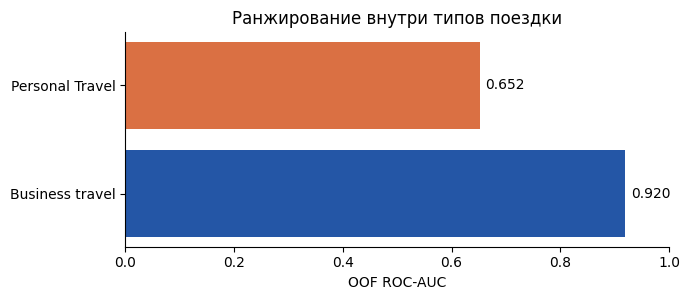

In [12]:
slices = pd.read_csv(output_dir / 'slices.csv')
travel = slices[slices.feature == 'Type of Travel'].copy()
display(travel[['value','n','positive_rate','roc_auc','error_rate']]
        .rename(columns={'value':'Тип поездки','n':'Строк','positive_rate':'Доля положительных',
                         'roc_auc':'ROC-AUC','error_rate':'Доля ошибок при 0,5'})
        .style.format({'Доля положительных':'{:.2%}','ROC-AUC':'{:.4f}', 'Доля ошибок при 0,5':'{:.2%}'}))
fig, ax = plt.subplots(figsize=(7, 3.1))
bars = ax.barh(travel['value'], travel['roc_auc'], color=[BLUE, ORANGE])
ax.bar_label(bars, fmt='%.3f', padding=4); ax.set_xlim(0, 1)
ax.set(xlabel='OOF ROC-AUC', title='Ранжирование внутри типов поездки')
plt.tight_layout(); plt.show()

В срезе личных поездок ROC-AUC ниже, чем в срезе деловых. Группы различаются и по доле положительных ответов, и по другим характеристикам. Это наблюдение задаёт направление для дальнейшего анализа, но не объясняет причину различия. Ошибки при одном пороге также зависят от состава классов и калибровки.

## 5. Выводы и следующие вопросы

Логистическая регрессия на исходных признаках даёт средний ROC-AUC 0,9216 на пяти стратифицированных фолдах. Эта модель служит точкой отсчёта. Она допускает уверенные ошибки и хуже ранжирует записи личных поездок.

Дальнейшие проверки:

1. Будет ли ROC-AUC одной модели LightGBM с заранее заданными настройками выше, чем у логистической регрессии на тех же фолдах, и как изменится время обучения?
2. Как изменится качество логистической регрессии, если исключить все 13 оценок сервисов и сохранить четыре остальные числовые и четыре категориальные колонки?
3. Сохранится ли направление разницы моделей при seeds 42, 13 и 73 и как изменятся ошибки по типу поездки и классу?

Эти вопросы пока не проверены. Любые сравнения нужно проводить на одинаковых разбиениях, фиксируя настройки до просмотра результатов. По этому набору нельзя установить реальную доступность признаков и независимость наблюдений или подтвердить перенос на другие данные.